In [1]:
pip install sentence-transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

c:\Users\Linzz\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df = pd.read_csv("../pertemuan-06/dataset_preprocessed.csv")
text_column = "clean_text"  # gunakan teks asli (sebelum preprocessing)
df = df.dropna(subset=[text_column])
sample_texts = df[text_column].head(100).astype(str).tolist()
print(f"Jumlah sample: {len(sample_texts)}")

Jumlah sample: 100


In [4]:
from gensim.models import Word2Vec

# Load model Word2Vec yang sudah dilatih sebelumnya
# (atau latih ulang jika diperlukan)
model_w2v = Word2Vec.load("../pertemuan-07/word2vec_model.bin")

# Kata yang sama dalam konteks berbeda
ambiguous_sentences = [
    "ular itu berbisa mematikan",
    "saya bisa berenang jauh",
    "obat itu manjur bisa menyembuhkan"
]

print("Demonstrasi Keterbatasan Static Embedding:")
print("=" * 60)
print("Kata 'bisa' selalu memiliki vektor yang SAMA:")

if "bisa" in model_w2v.wv:
    vec = model_w2v.wv["bisa"]
    print(f"  Vektor 'bisa' (10 dim pertama): {vec[:10].round(3)}")
else:
    print("  Kata 'bisa' tidak ada dalam vocabulary model ini.")
    print("  Gunakan kata lain yang tersedia sebagai contoh.")

Demonstrasi Keterbatasan Static Embedding:
Kata 'bisa' selalu memiliki vektor yang SAMA:
  Kata 'bisa' tidak ada dalam vocabulary model ini.
  Gunakan kata lain yang tersedia sebagai contoh.


In [5]:
# Model multilingual yang mendukung Bahasa Indonesia
model_st = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
print("Model Sentence Transformer berhasil dimuat.")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1178.77it/s]


Model Sentence Transformer berhasil dimuat.


In [6]:
# Encode kalimat menjadi vektor
embeddings = model_st.encode(sample_texts, show_progress_bar=True)

print(f"Shape embeddings: {embeddings.shape}")
print(f"Dimensi per kalimat: {embeddings.shape[1]}")

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Batches: 100%|██████████| 4/4 [00:13<00:00,  3.41s/it]

Shape embeddings: (100, 384)
Dimensi per kalimat: 384


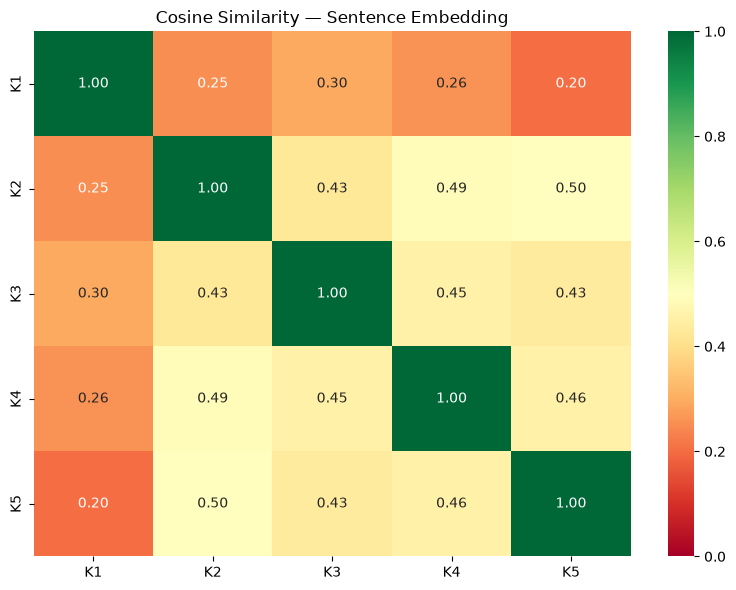

K1: deretan aktor yang pernah perankan spiderman...
K2: aktor ryotaro shimizu ditemukan meninggal dunia di kediamannya...
K3: aktor marvelous mrs maisel josh grisetti meninggal dunia...
K4: aktor bittersweet destiny wang kai ditemukan meninggal dunia di rumahnya...
K5: aktor thailand jorjay phumhirun mendadak meninggal di usia tahun...


In [7]:
# Ambil 5 kalimat pertama
test_sentences = sample_texts[:5]
test_embeddings = model_st.encode(test_sentences)

# Hitung cosine similarity
sim_matrix = cosine_similarity(test_embeddings)

# Visualisasi
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0, vmax=1,
    xticklabels=[f"K{i+1}" for i in range(5)],
    yticklabels=[f"K{i+1}" for i in range(5)]
)
plt.title("Cosine Similarity — Sentence Embedding")
plt.tight_layout()
plt.show()

# Tampilkan kalimat
for i, text in enumerate(test_sentences):
    print(f"K{i+1}: {text[:80]}...")

In [8]:
# Kata ambigu dalam konteks berbeda
context_pairs = [
    ("Bunga mawar merah itu sangat indah.", "Bunga tabungan bank naik bulan ini."),
    ("Kita harus bisa menyelesaikan masalah ini.", "Ular kobra itu sangat berbisa."),
    ("Dia pergi ke bank untuk menabung.", "Mereka duduk di tepi kali yang jernih."),
]

print("Perbandingan Semantic Similarity Konteks Berbeda:")
print("=" * 60)
for s1, s2 in context_pairs:
    e1 = model_st.encode([s1])
    e2 = model_st.encode([s2])
    sim = cosine_similarity(e1, e2)[0][0]
    print(f"\nK1: {s1}")
    print(f"K2: {s2}")
    print(f"Similarity: {sim:.4f} ({'mirip' if sim > 0.7 else 'berbeda'})")

Perbandingan Semantic Similarity Konteks Berbeda:

K1: Bunga mawar merah itu sangat indah.
K2: Bunga tabungan bank naik bulan ini.
Similarity: 0.0560 (berbeda)

K1: Kita harus bisa menyelesaikan masalah ini.
K2: Ular kobra itu sangat berbisa.
Similarity: -0.0270 (berbeda)

K1: Dia pergi ke bank untuk menabung.
K2: Mereka duduk di tepi kali yang jernih.
Similarity: 0.0549 (berbeda)


In [9]:
def semantic_search(query, corpus_embeddings, corpus_texts, top_n=5):
    query_embedding = model_st.encode([query])
    similarities = cosine_similarity(query_embedding, corpus_embeddings)[0]
    top_indices = similarities.argsort()[::-1][:top_n]
    results = []
    for idx in top_indices:
        results.append({
            "score": similarities[idx],
            "text": corpus_texts[idx]
        })
    return results

# Contoh pencarian semantik
query = "pelayanan hotel yang memuaskan"
results = semantic_search(query, embeddings, sample_texts)

print(f"Query: '{query}'")
print("=" * 60)
for i, res in enumerate(results, 1):
    print(f"\n{i}. [Score: {res['score']:.4f}]")
    print(f"   {res['text'][:120]}...")

Query: 'pelayanan hotel yang memuaskan'

1. [Score: 0.3452]
   jakone mobile jadi andalan transformasi digital bank jakarta...

2. [Score: 0.3291]
   bank jakarta perluas layanan digital untuk dukung ekosistem persija...

3. [Score: 0.3213]
   bni hadirkan ekosistem keuangan digital bagi mahasiswa indonesia di hong kong...

4. [Score: 0.2959]
   bank aladin syariah perkuat layanan digital nasabah tembus juta...

5. [Score: 0.2923]
   kolaborasi digital dan syariah dinilai perkuat industri dana pensiun...


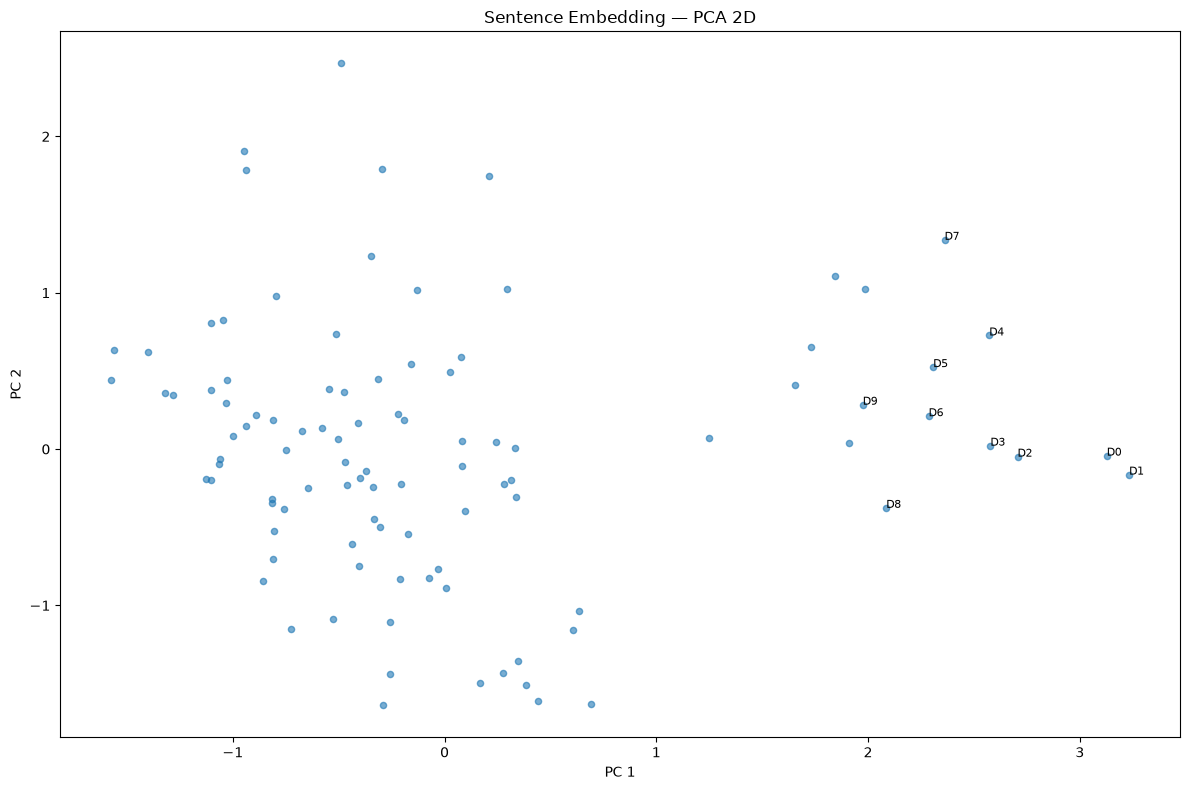

Variansi yang dijelaskan: 19.78%


In [10]:
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], alpha=0.6, s=20)

# Highlight beberapa dokumen
for i in range(min(10, len(sample_texts))):
    plt.annotate(
        f"D{i}",
        xy=(embeddings_2d[i, 0], embeddings_2d[i, 1]),
        fontsize=8
    )

plt.title("Sentence Embedding — PCA 2D")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.tight_layout()
plt.show()

print(f"Variansi yang dijelaskan: {pca.explained_variance_ratio_.sum():.2%}")

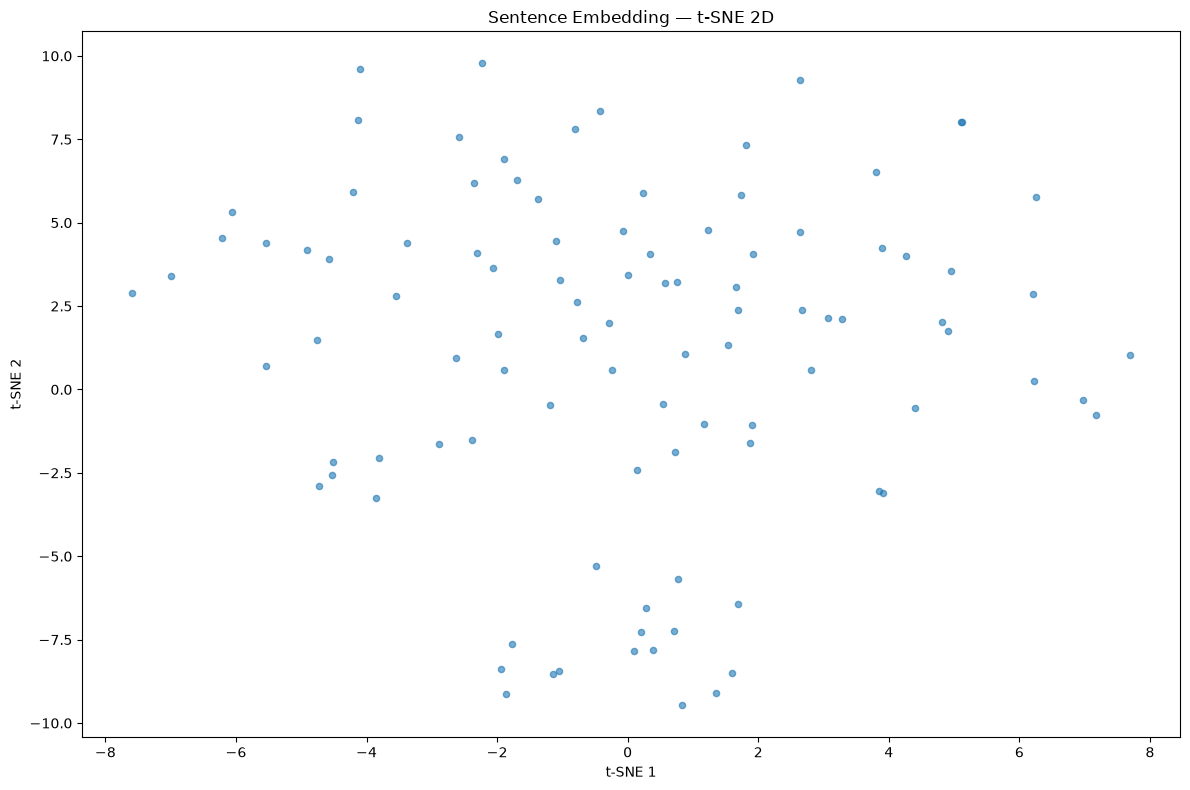

In [11]:
tsne = TSNE(n_components=2, perplexity=20, random_state=42, max_iter=1000)
embeddings_tsne = tsne.fit_transform(embeddings)

plt.figure(figsize=(12, 8))
plt.scatter(embeddings_tsne[:, 0], embeddings_tsne[:, 1], alpha=0.6, s=20)
plt.title("Sentence Embedding — t-SNE 2D")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

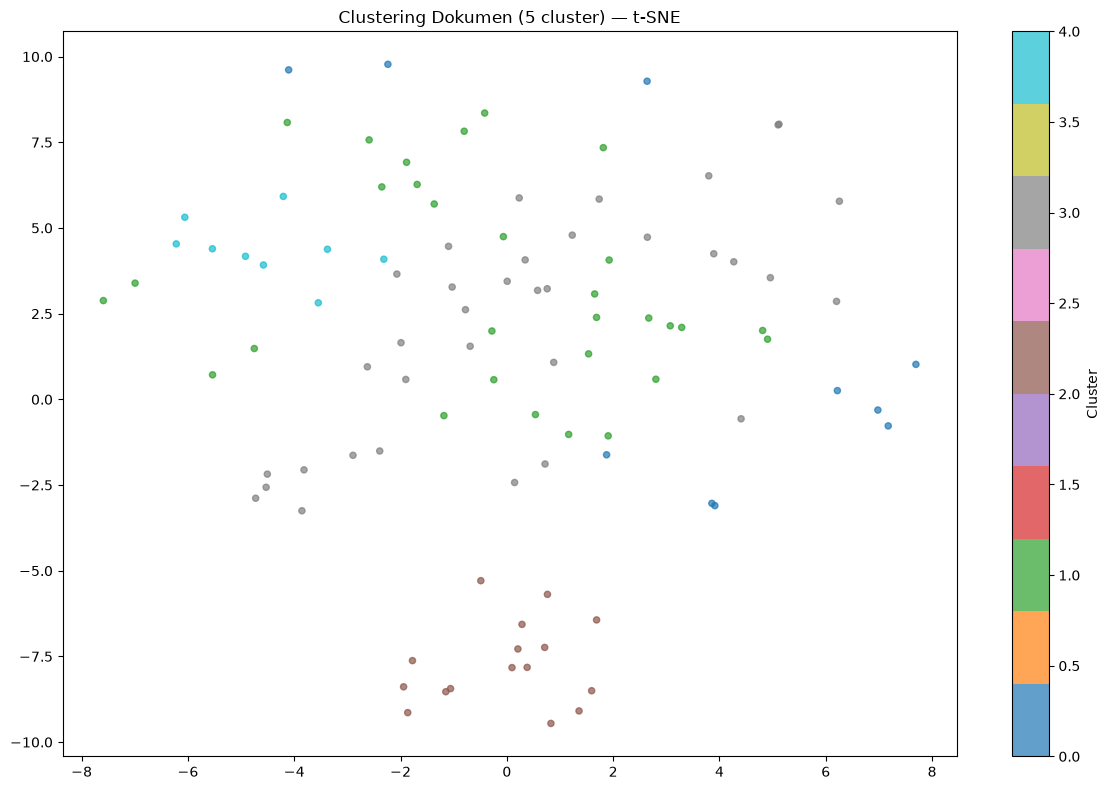


Cluster 0 (contoh dokumen):
  - menyintas era digital dengan imunitas kebudayaan...
  - antropolog as soroti beban moral santriwati di ruang digital...
  - pencegahan radikalisme di ruang digital butuh kolaborasi lintas kementerian...

Cluster 1 (contoh dokumen):
  - platform digital global diminta ikut biayai infrastruktur digital nasional...
  - kerugian penipuan digital capai rp triliun perusahaan perkuat digital trust...
  - memutus ekosistem kejahatan keuangan digital...

Cluster 2 (contoh dokumen):
  - deretan aktor yang pernah perankan spiderman...
  - aktor ryotaro shimizu ditemukan meninggal dunia di kediamannya...
  - aktor marvelous mrs maisel josh grisetti meninggal dunia...

Cluster 3 (contoh dokumen):
  - lintasarta dorong transformasi digital bpd lewat fondasi digital berdaulat...
  - telkomgroup nongsa digital park dan bw digital perkuat gerbang digital indonesia...
  - sim digital gagal muncul begini cara mengatasinya...

Cluster 4 (contoh dokumen):
  - gandeng edb si

In [12]:
from sklearn.cluster import KMeans

# Cluster dokumen menjadi 5 kelompok
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(embeddings)

# Visualisasi cluster
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    c=cluster_labels,
    cmap="tab10",
    alpha=0.7,
    s=20
)
plt.colorbar(scatter, label="Cluster")
plt.title(f"Clustering Dokumen ({n_clusters} cluster) — t-SNE")
plt.tight_layout()
plt.show()

# Contoh dokumen per cluster
for cluster_id in range(n_clusters):
    indices = np.where(cluster_labels == cluster_id)[0][:3]
    print(f"\nCluster {cluster_id} (contoh dokumen):")
    for idx in indices:
        print(f"  - {sample_texts[idx][:80]}...")